# Top-K activating images for SAE neurons

For every SAE neuron kept after pruning, we show the K training images that activate it most strongly.

- The **heatmap** projects the backbone's last feature map (`layer4`, 7×7) onto the neuron's decoder direction. Bright regions are where the neuron's direction is present; everything else is dimmed.
- Under each image: its class and the neuron's activation value.
- The bar chart shows which classes dominate the top activations. A neuron spread over many classes is more likely a shared visual concept; one dominated by a single class may just be a class detector.

Run the pipeline first (see `README.md`). By default this notebook uses the most recent SAE run in `outputs/sae/`.

In [1]:
%matplotlib inline
%config InlineBackend.figure_format = 'jpeg'

import ipywidgets as widgets
import matplotlib.pyplot as plt
from IPython.display import Image, display

from concept_learning.topk import NeuronExplorer, latest_run

SAE_DIR = latest_run("sae")
explorer = NeuronExplorer(SAE_DIR)
print(f"SAE run: {SAE_DIR.name}")
print(f"Backbone: {explorer.activation_info['backbone']}")

SAE run: sae_resnet18_cub_20261122_144103
Backbone: resnet18_cub


## Run summary

In [2]:
m = explorer.metrics
p = m["pruning"]
summary = {
    "classifier accuracy (train / val / test)": " / ".join(f"{explorer.activation_info['classifier_accuracy'][s]:.2%}" for s in ["train", "val", "test"]),
    "SAE neurons": m["n_neurons"],
    "kept after pruning": p["kept_neurons"],
    "val reconstruction MSE": f"{m['val_reconstruction_loss']:.5f}",
    "val avg L0 (active neurons per image)": f"{m['val_avg_l0']:.2f}",
    "recovered accuracy, all neurons": f"{p['baseline_recovered_accuracy']:.2%}",
    "recovered accuracy, kept neurons": f"{p['selected_recovered_accuracy']:.2%}",
}
for key, value in summary.items():
    print(f"{key:>42}: {value}")

  classifier accuracy (train / val / test): 99.87% / 73.83% / 72.23%
                               SAE neurons: 512
                        kept after pruning: 233
                    val reconstruction MSE: 0.24797
     val avg L0 (active neurons per image): 10.94
           recovered accuracy, all neurons: 88.18%
          recovered accuracy, kept neurons: 87.73%


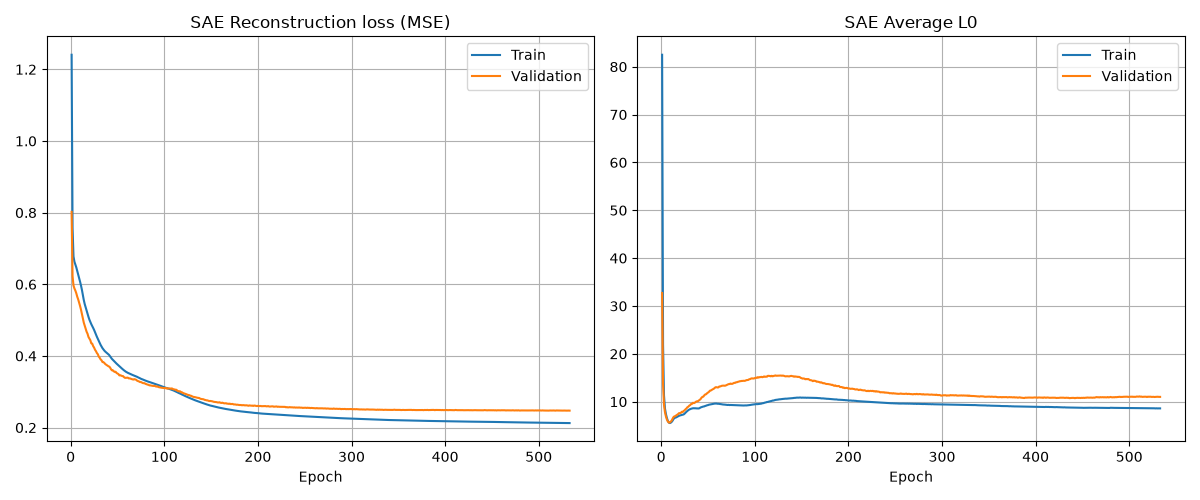

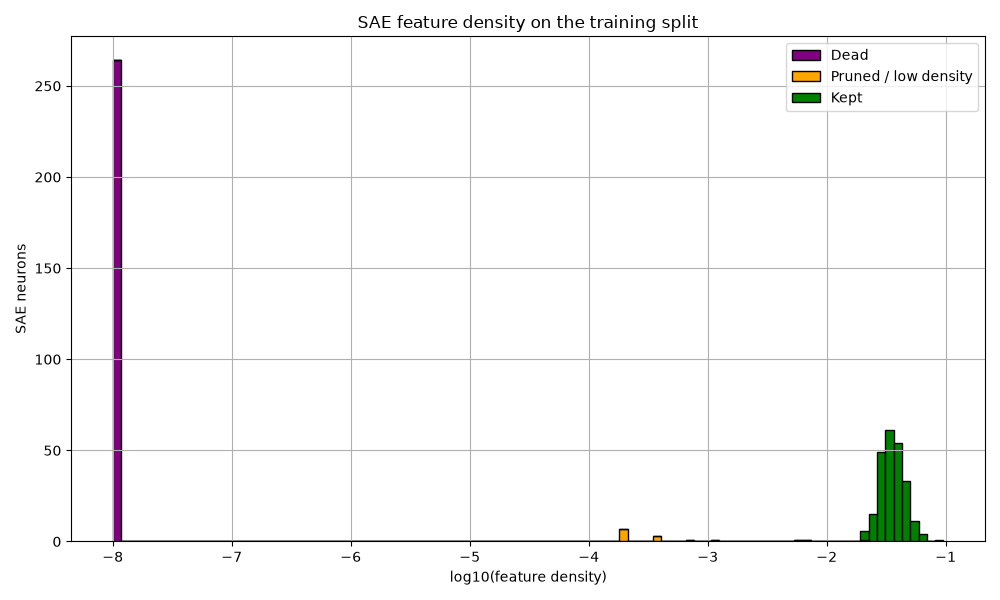

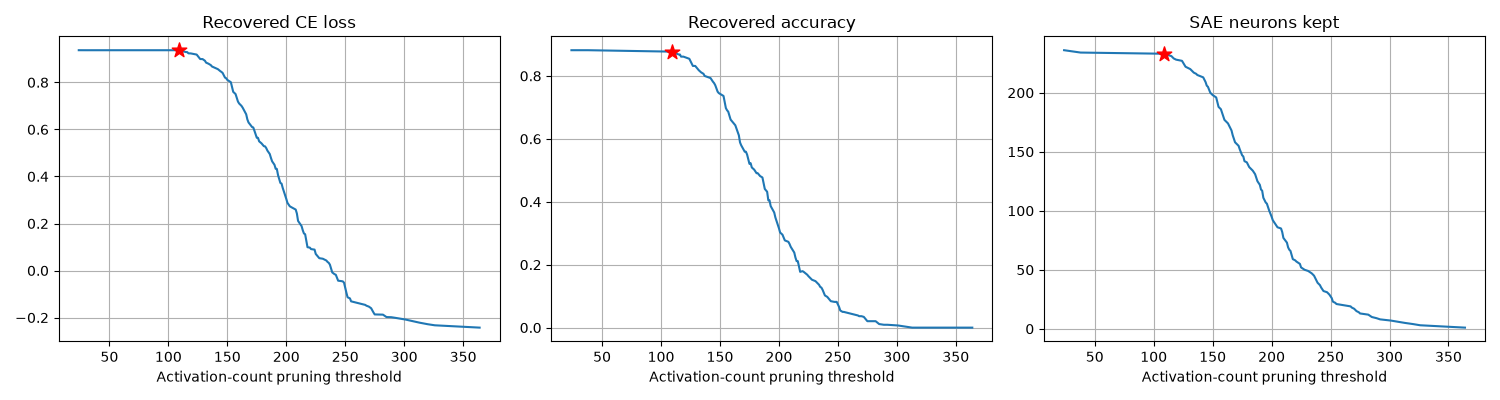

In [3]:
for plot in ["training_curves", "feature_density", "pruning_curve"]:
    display(Image(filename=SAE_DIR / "plots" / f"{plot}.png", width=900))

## Class purity

An SAE neuron is only a candidate *concept* if it is shared across classes. For each kept neuron we take its top 10 activating training images and measure the share of the most common class:

- **class detector**: one class makes up at least 80% of the top 10;
- **diffuse**: the top 10 spans at least 8 classes, so there is no dominant class (and often no visible common feature either);
- `within_class_variance`: the share of the embeddings' variance left within classes. Near 0 means each class has collapsed onto its mean, and the cheapest sparse code is then "one neuron per class".

The table compares this notebook's run with the latest L1 sweeps in `outputs/sae_sweep/` for our ResNet-18 and for the M-CBM authors' model (`resnet18_cub_pytorchcv`), when they exist.

In [4]:
import pandas as pd

from concept_learning.purity import class_purity

purity_runs = {"this notebook": SAE_DIR}
for backbone in ["resnet18_cub", "resnet18_cub_pytorchcv"]:
    try:
        sweep = latest_run("sae_sweep", backbone)
    except FileNotFoundError:
        continue
    for run in sorted(sweep.glob("l1_*"), key=lambda p: float(p.name.removeprefix("l1_"))):
        purity_runs[f"{sweep.name}/{run.name}"] = run

purity = {name: class_purity(run) for name, run in purity_runs.items()}
purity_table = pd.DataFrame({name: summary for name, (summary, _) in purity.items()}).T
purity_table.style.format(
    {
        "l1_coefficient": "{:g}",
        "train_avg_l0": "{:.2f}",
        "class_detectors": "{:.0%}",
        "diffuse_neurons": "{:.0%}",
        "mean_top10_share": "{:.2f}",
        "mean_top50_share": "{:.2f}",
        "within_class_variance": "{:.0%}",
    }
)

,backbone,l1_coefficient,train_avg_l0,kept_neurons,class_detectors,classes_with_detector,diffuse_neurons,mean_top10_share,mean_top50_share,within_class_variance
this notebook,resnet18_cub,0.008,8.56,233,65%,149,11%,0.78,0.40,48%
sweep_resnet18_cub_20261122_141831/l1_0.0005,resnet18_cub,0.0005,149.46,469,32%,126,20%,0.56,0.29,48%
sweep_resnet18_cub_20261122_141831/l1_0.001,resnet18_cub,0.001,79.50,421,32%,115,17%,0.58,0.29,48%
sweep_resnet18_cub_20261122_141831/l1_0.002,resnet18_cub,0.002,40.00,417,36%,134,21%,0.59,0.30,48%
sweep_resnet18_cub_20261122_141831/l1_0.004,resnet18_cub,0.004,20.41,375,43%,152,18%,0.62,0.32,48%
sweep_resnet18_cub_20261122_141831/l1_0.008,resnet18_cub,0.008,8.56,233,65%,149,11%,0.78,0.40,48%
sweep_resnet18_cub_20261122_141831/l1_0.016,resnet18_cub,0.016,2.89,109,65%,71,1%,0.81,0.45,48%
sweep_resnet18_cub_pytorchcv_20261122_145612/l1_0.002,resnet18_cub_pytorchcv,0.002,7.44,354,77%,200,13%,0.84,0.45,10%
sweep_resnet18_cub_pytorchcv_20261122_145612/l1_0.008,resnet18_cub_pytorchcv,0.008,1.41,136,92%,125,0%,0.95,0.62,10%


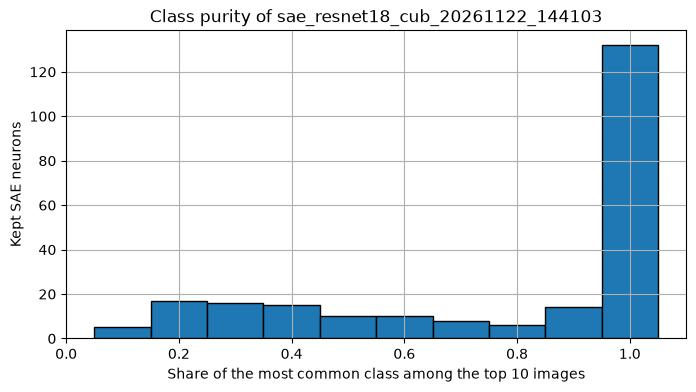

In [5]:
_, neuron_purity = purity["this notebook"]
plt.figure(figsize=(8, 4))
plt.hist([row["share"] for row in neuron_purity], bins=[(i + 0.5) / 10 for i in range(11)], edgecolor="black")
plt.xlabel("Share of the most common class among the top 10 images")
plt.ylabel("Kept SAE neurons")
plt.title(f"Class purity of {SAE_DIR.name}")
plt.grid(True)
plt.show()

### Findings (runs from 2026-11-22)

- **Most kept neurons are class detectors, and the L1 coefficient is not the cause.** Across our sweep (L1 from 0.0005 to 0.008) the *number* of detectors stays around 135–165, almost each for a different class. A stronger L1 only removes the other neurons, so the detectors' *share* grows (32% → 65%).
- **The M-CBM authors' model is even more class-specific.** At the paper's setting (L1 = 0.002, L0 ≈ 7.4) 77% of its kept neurons are class detectors, and they cover all 200 classes. Its training embeddings keep only about 10% of their variance within classes: it was trained on the whole training split and has memorised it. Ours keeps about 48%.
- **An SAE on the pooled penultimate-layer embedding of a CUB classifier therefore largely rediscovers the classes.** Shared concepts exist but are a minority. The class bar chart under each neuron is the easiest place to spot them. For example, neuron 131 is dominated by Lazuli Bunting, but its other top classes (Florida Jay, Tree Swallow, Cerulean Warbler, Indigo Bunting) are all blue birds, so it encodes "blue plumage" more than the class itself.
- **Top-K by activation favours each concept's most prototypical class,** so the top 10 looks more class-specific than the neuron really is. The mean share of the most common class drops sharply from the top 10 to the top 50.

## Browse SAE neurons

Interactive picker. It only works in a live kernel; GitHub doesn't render widgets, so the static gallery below is what shows up in the committed notebook.

In [6]:
neuron_picker = widgets.Dropdown(
    options=[(f"neuron {u} (fires on {int(explorer.neuron_counts[u])} images)", u) for u in explorer.neurons_by_frequency()],
    description="Neuron",
    layout=widgets.Layout(width="420px"),
)
k_slider = widgets.IntSlider(value=10, min=5, max=30, step=5, description="K")
heatmap_toggle = widgets.Checkbox(value=True, description="Heatmap")


def show(neuron, k, heatmap):
    explorer.plot_neuron(neuron, k=k, heatmap=heatmap)
    plt.show()


output = widgets.interactive_output(show, {"neuron": neuron_picker, "k": k_slider, "heatmap": heatmap_toggle})
display(widgets.HBox([neuron_picker, k_slider, heatmap_toggle]), output)

Output()

## Static gallery

The `N_NEURONS` most frequently firing kept neurons, plus a random sample of the rest, so rarer (often more specific) neurons get shown too.

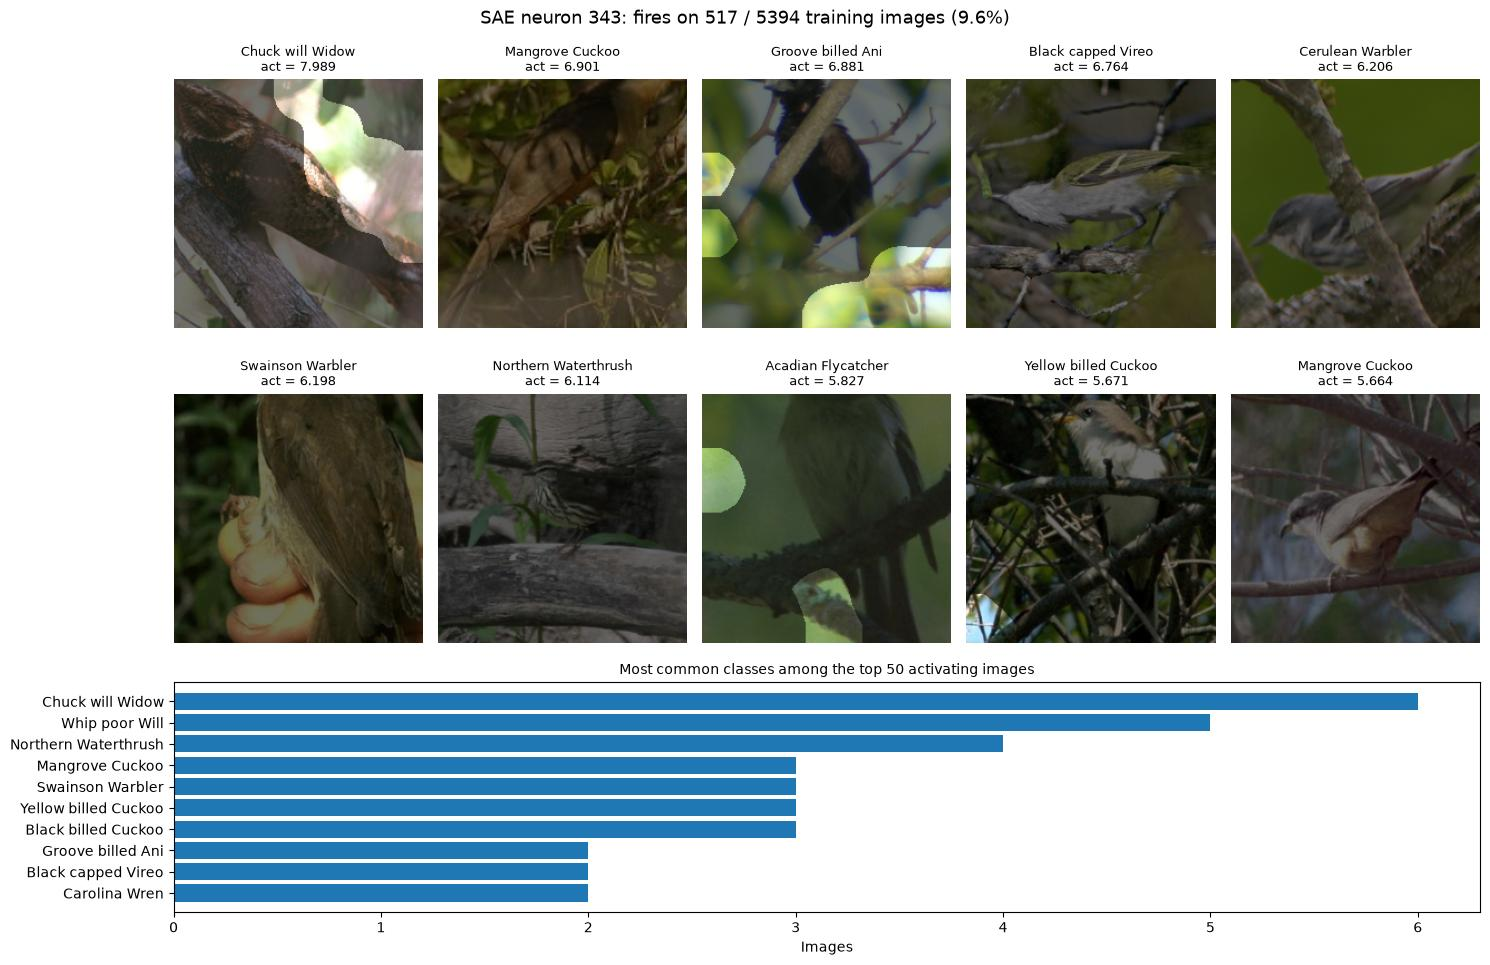

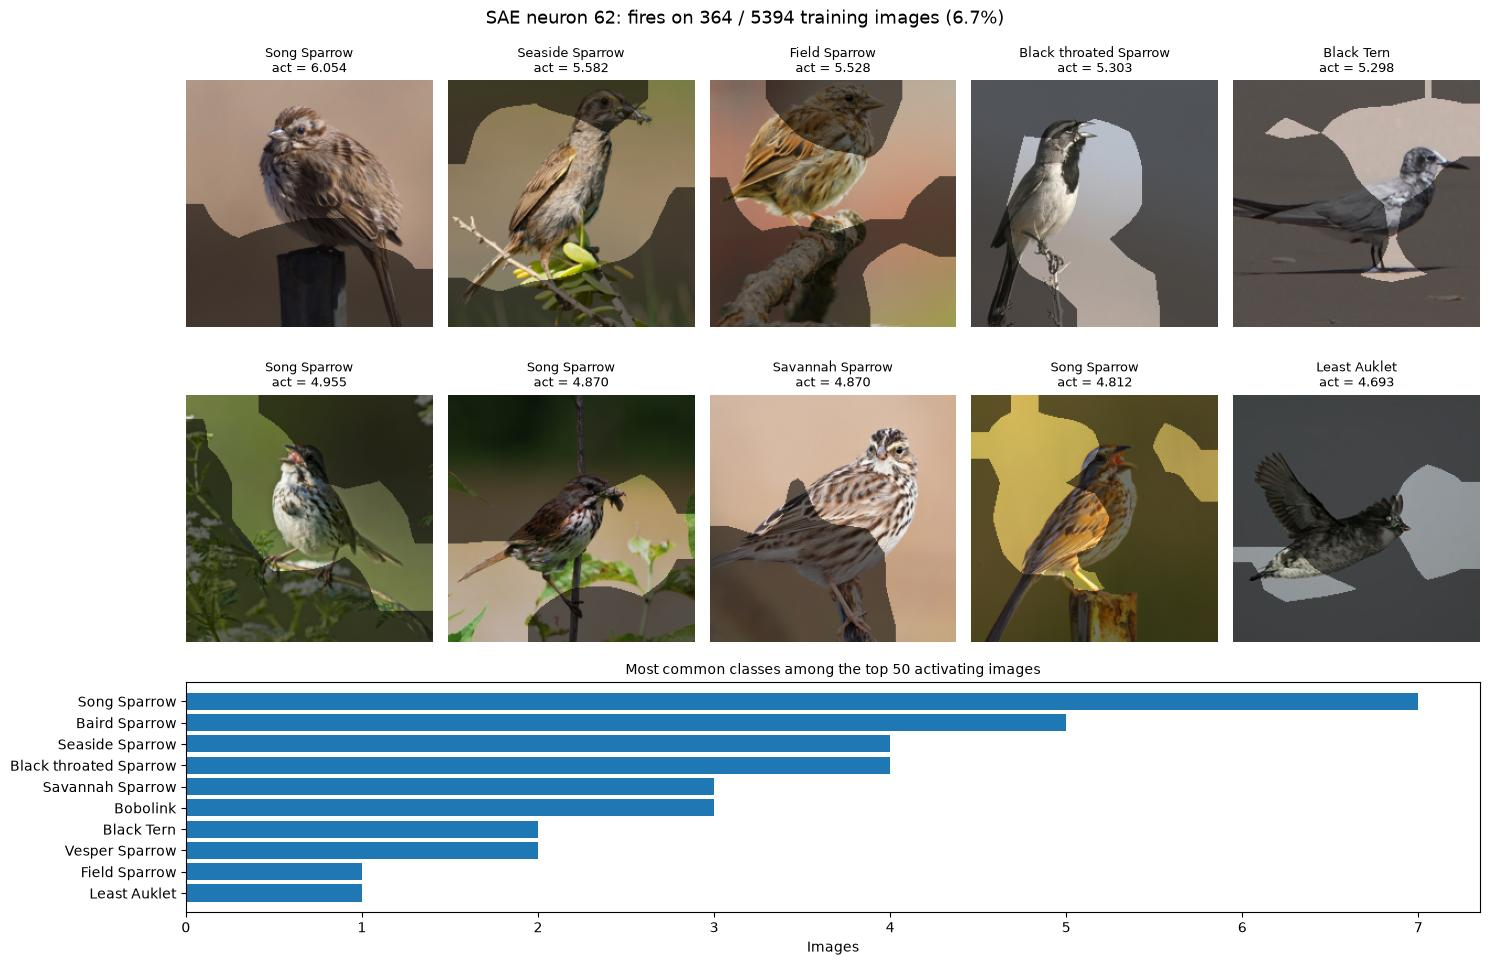

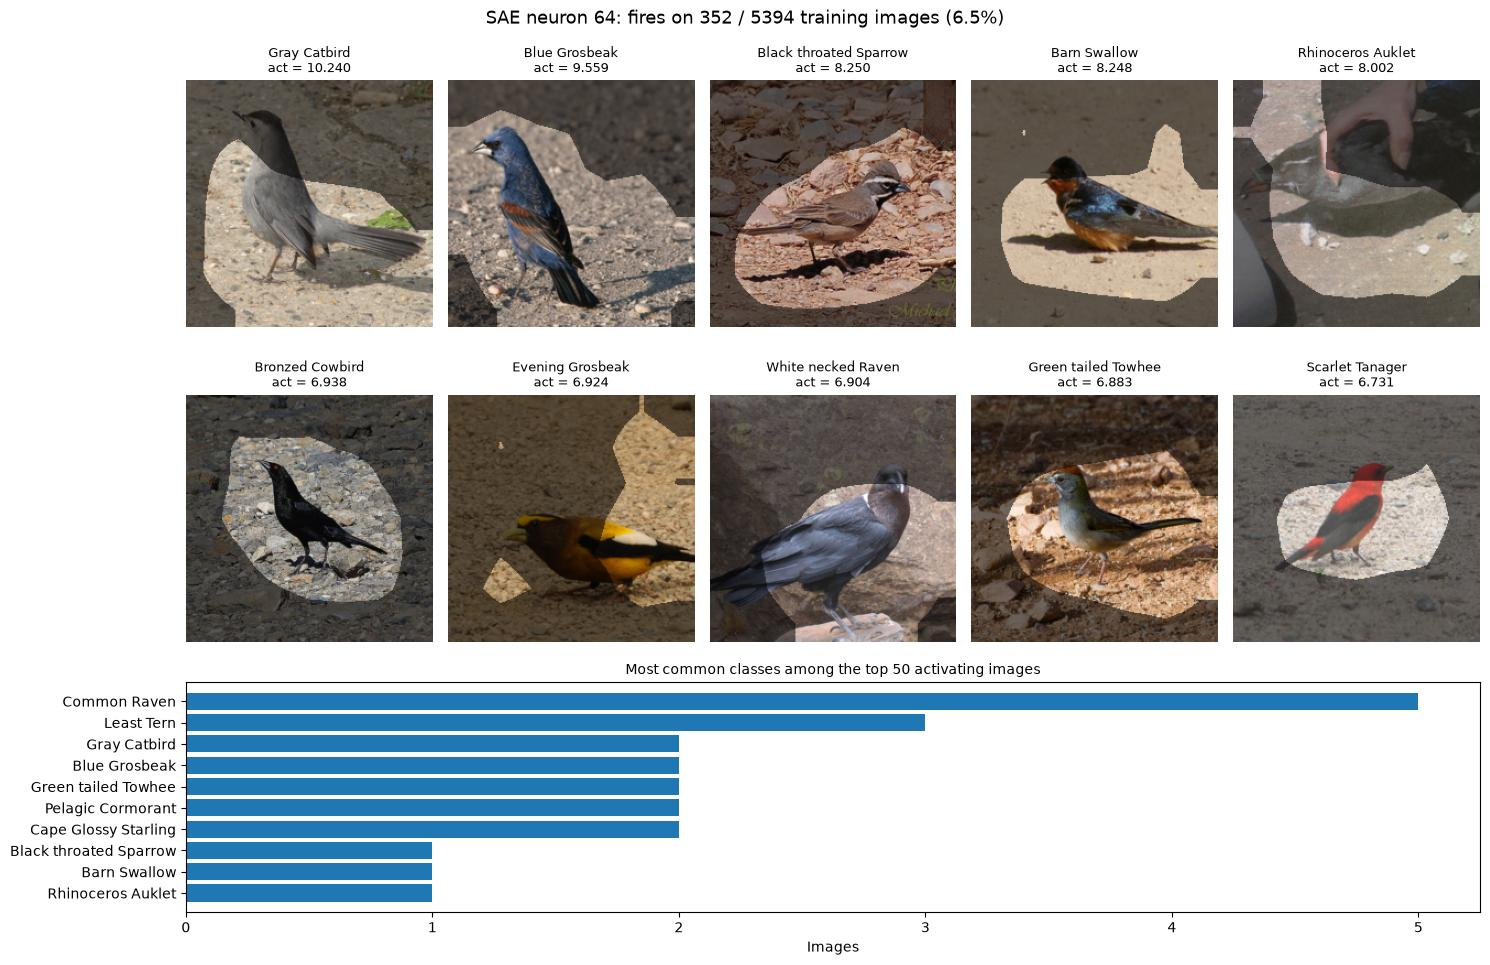

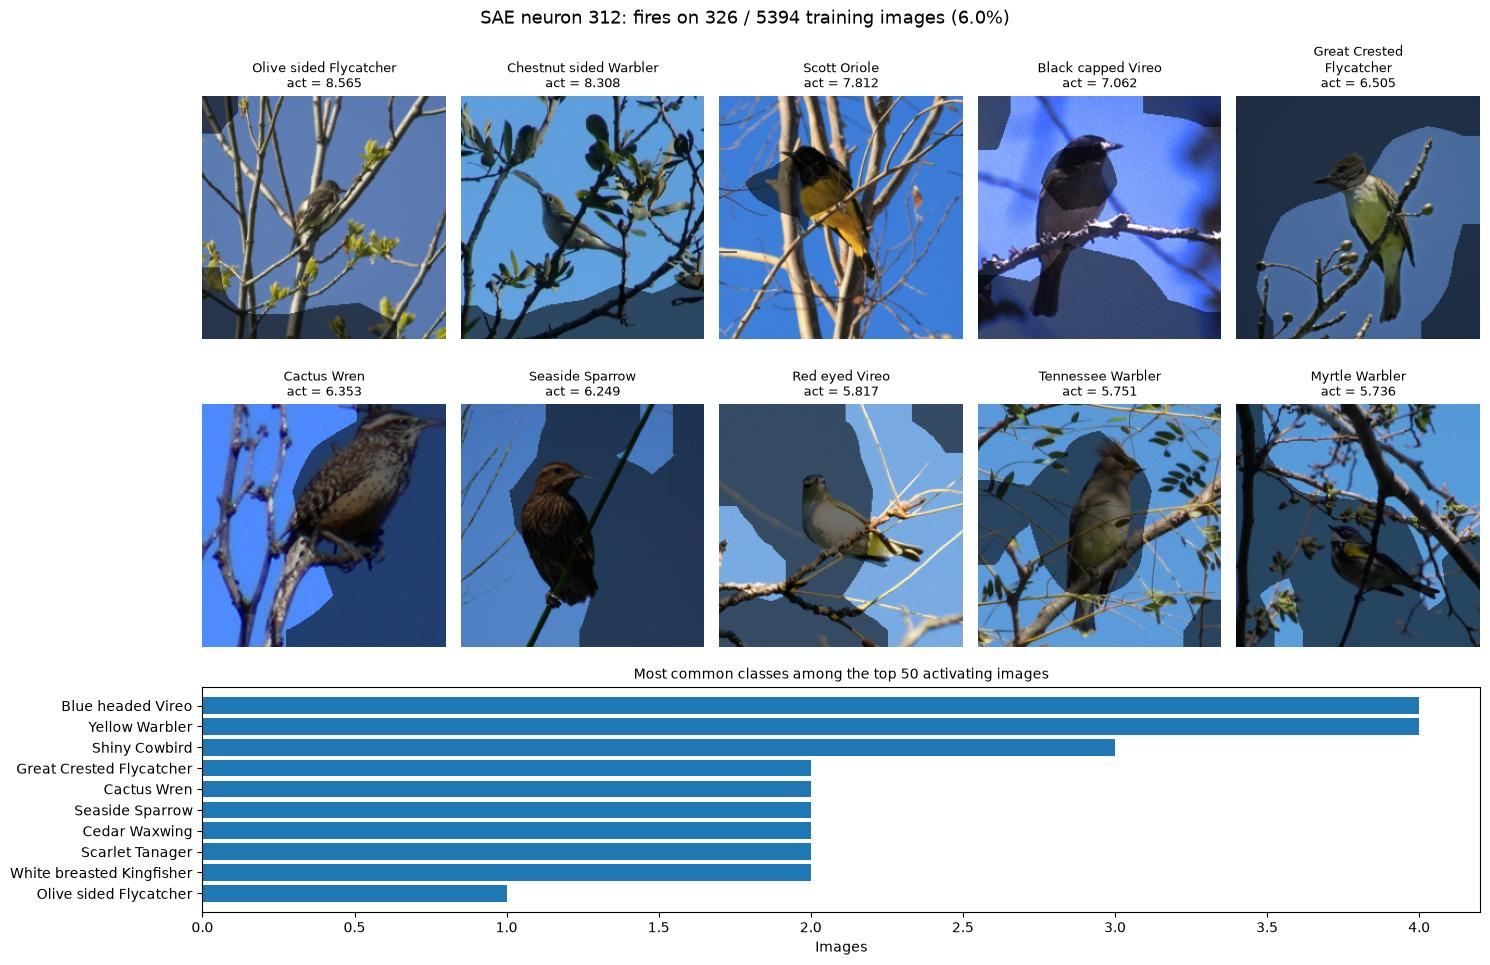

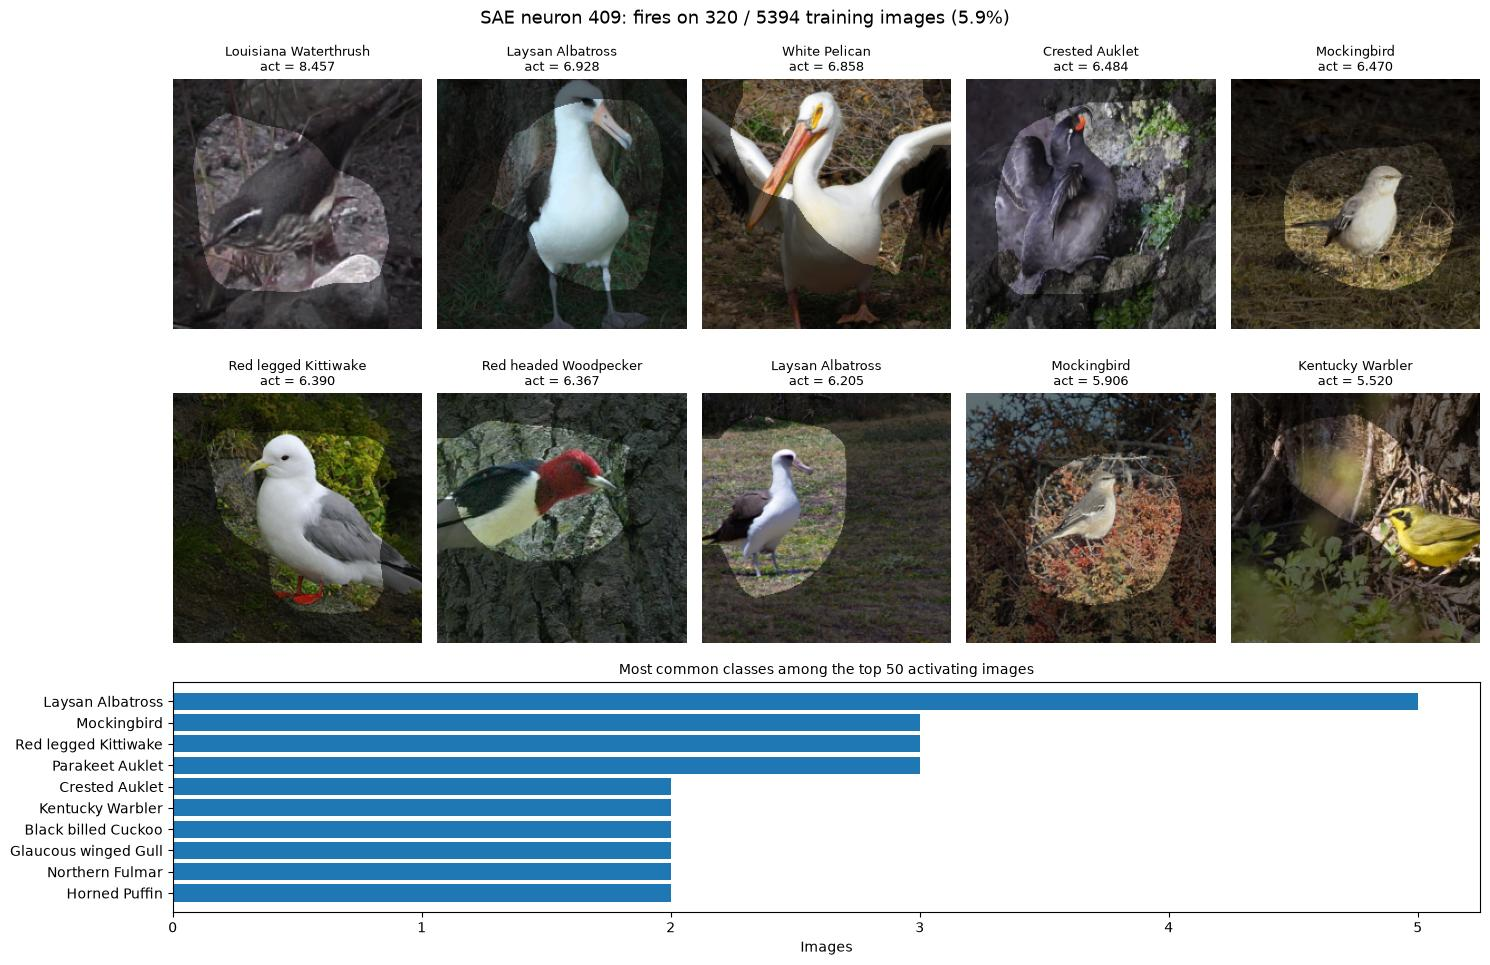

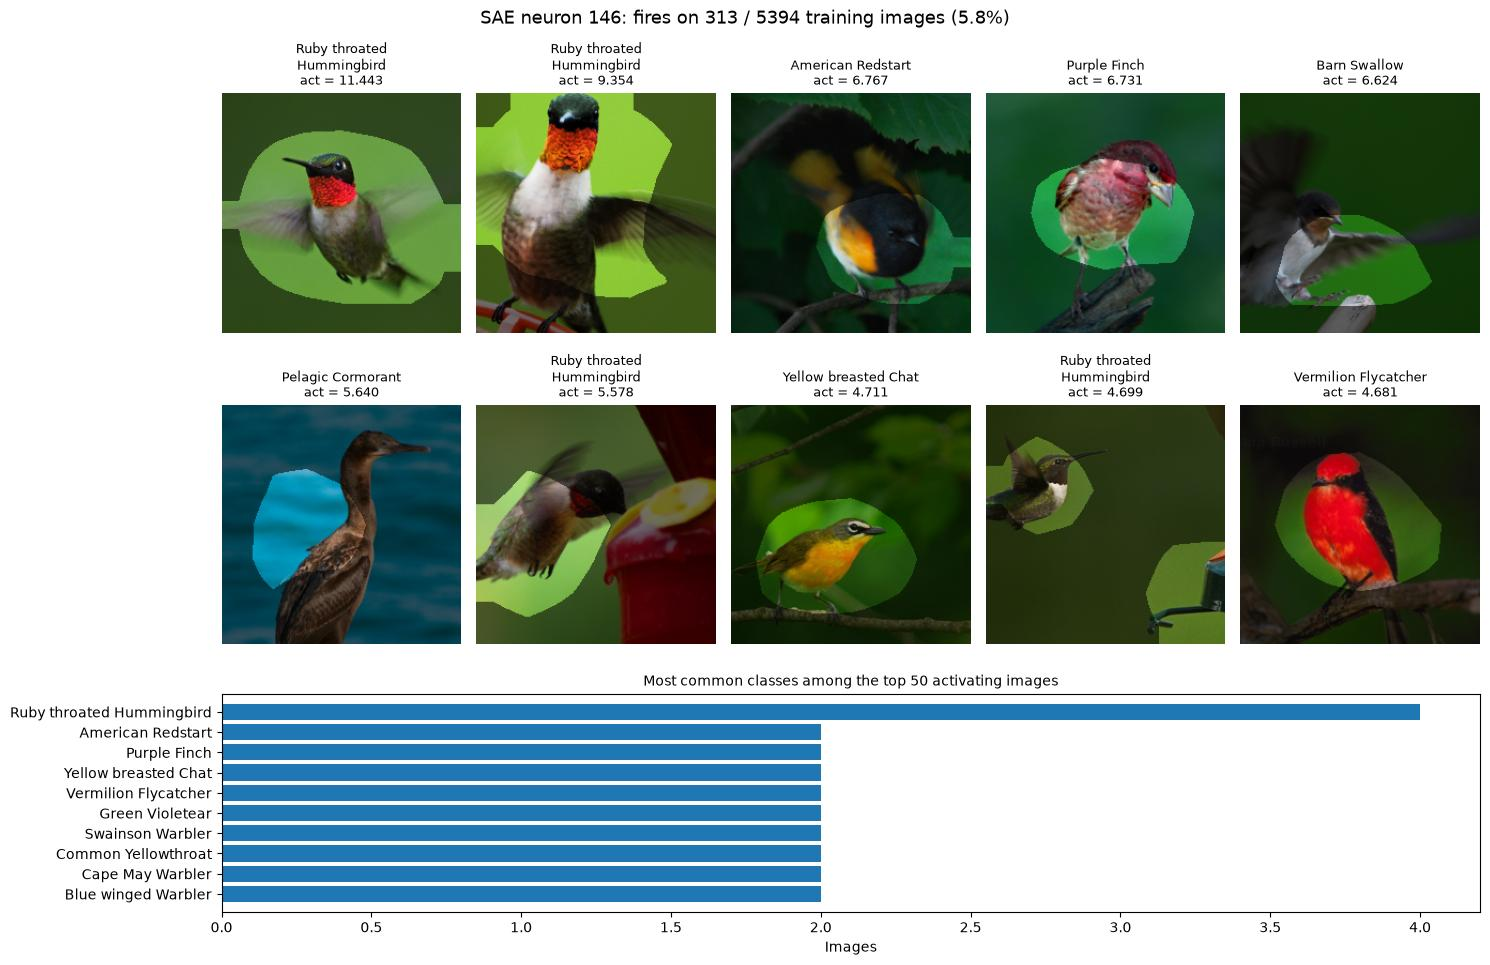

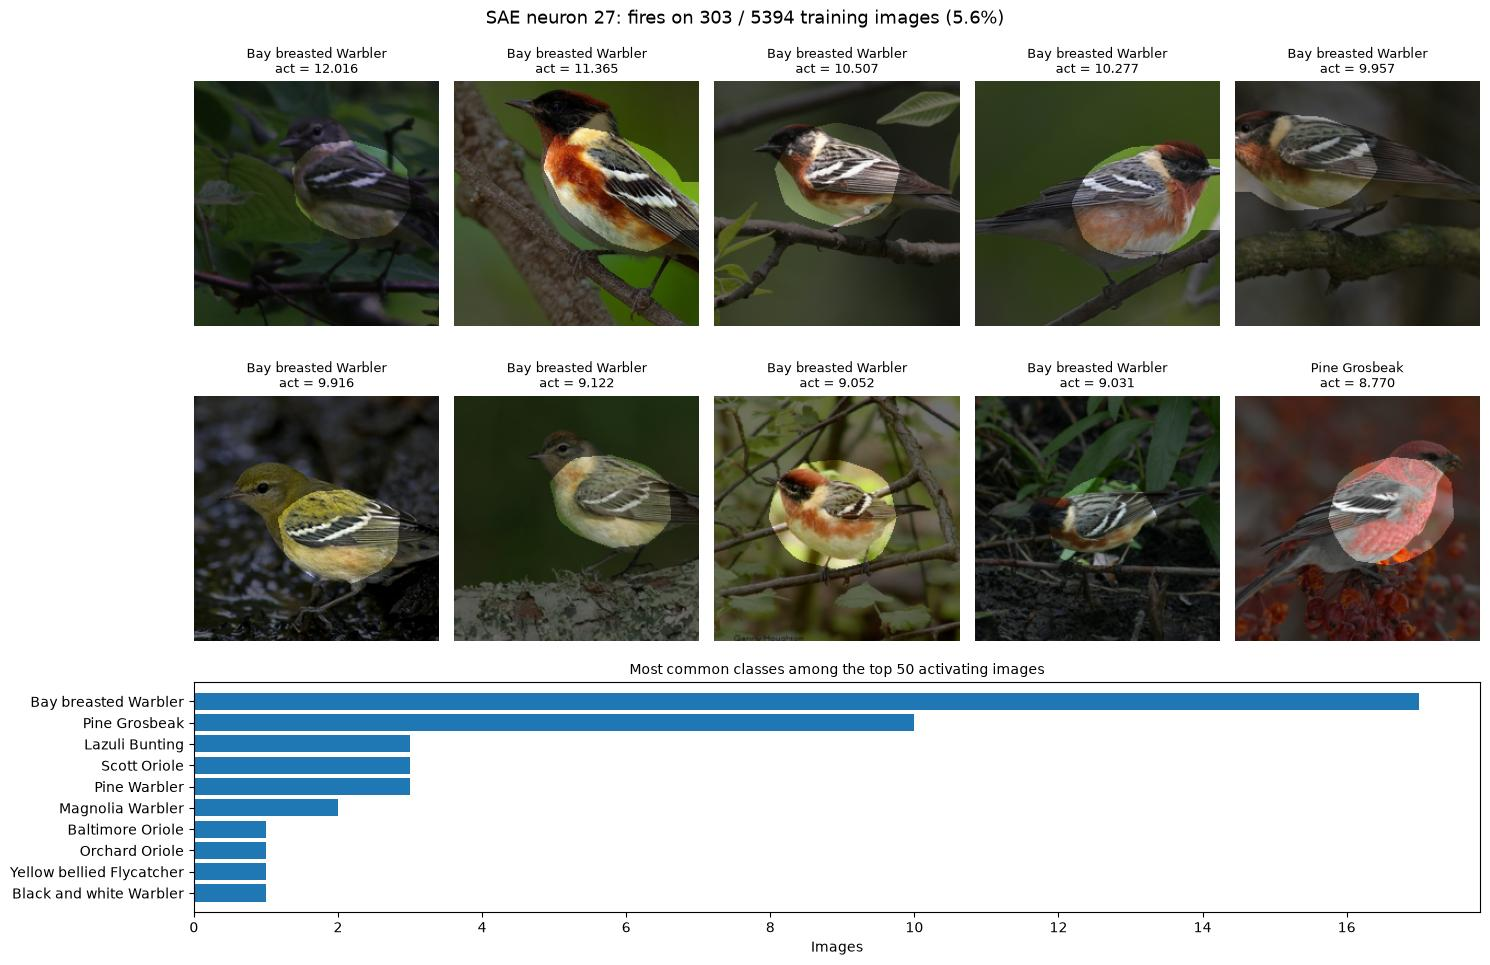

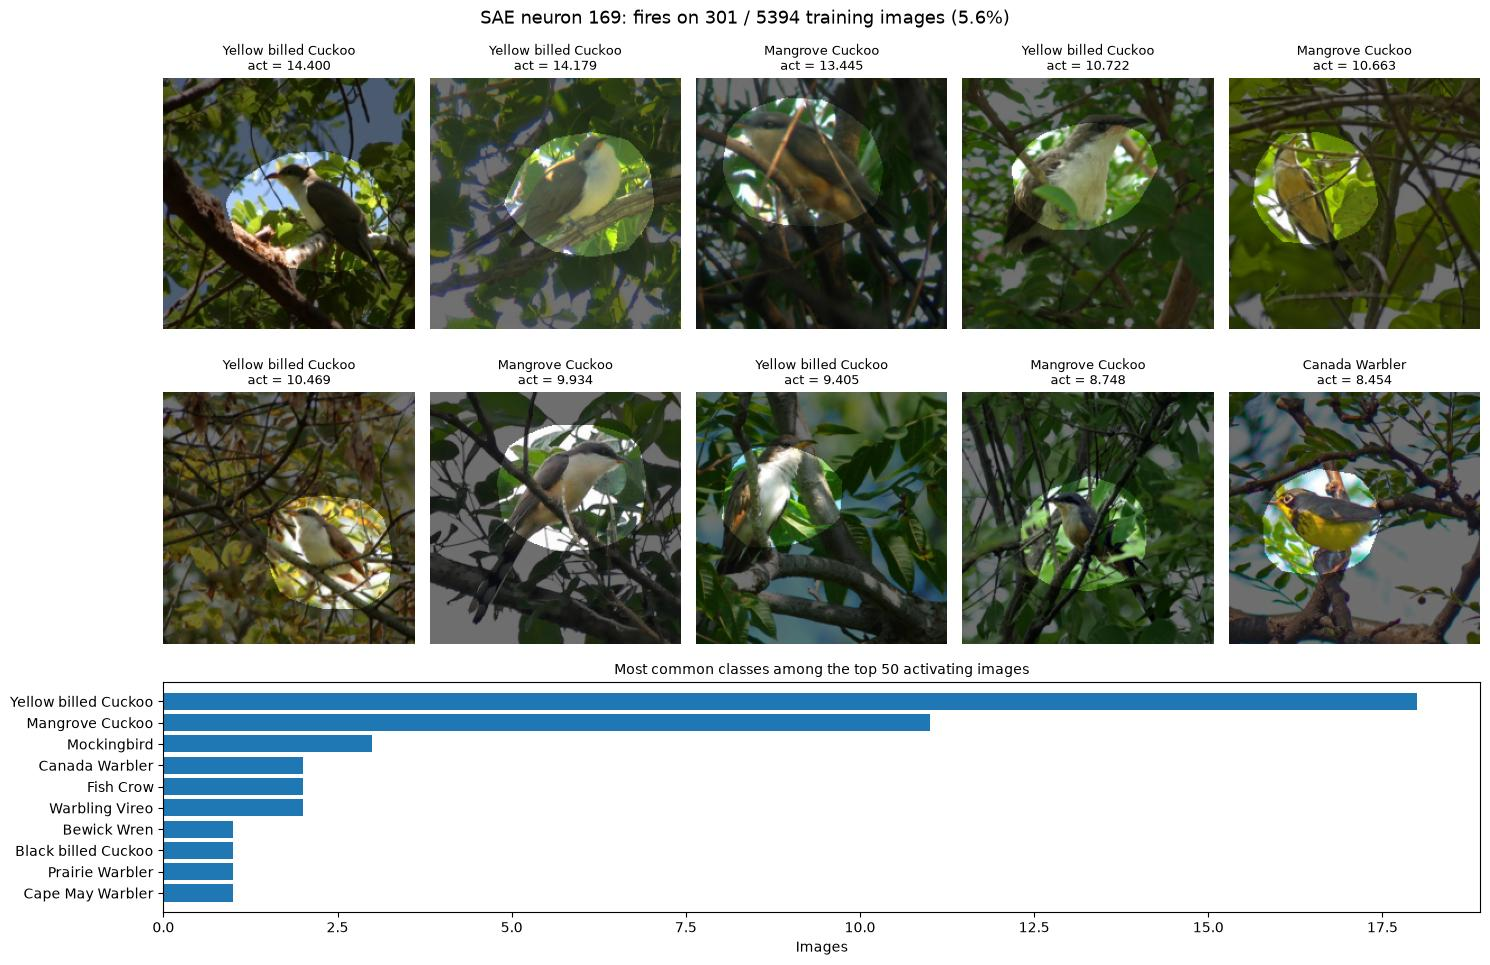

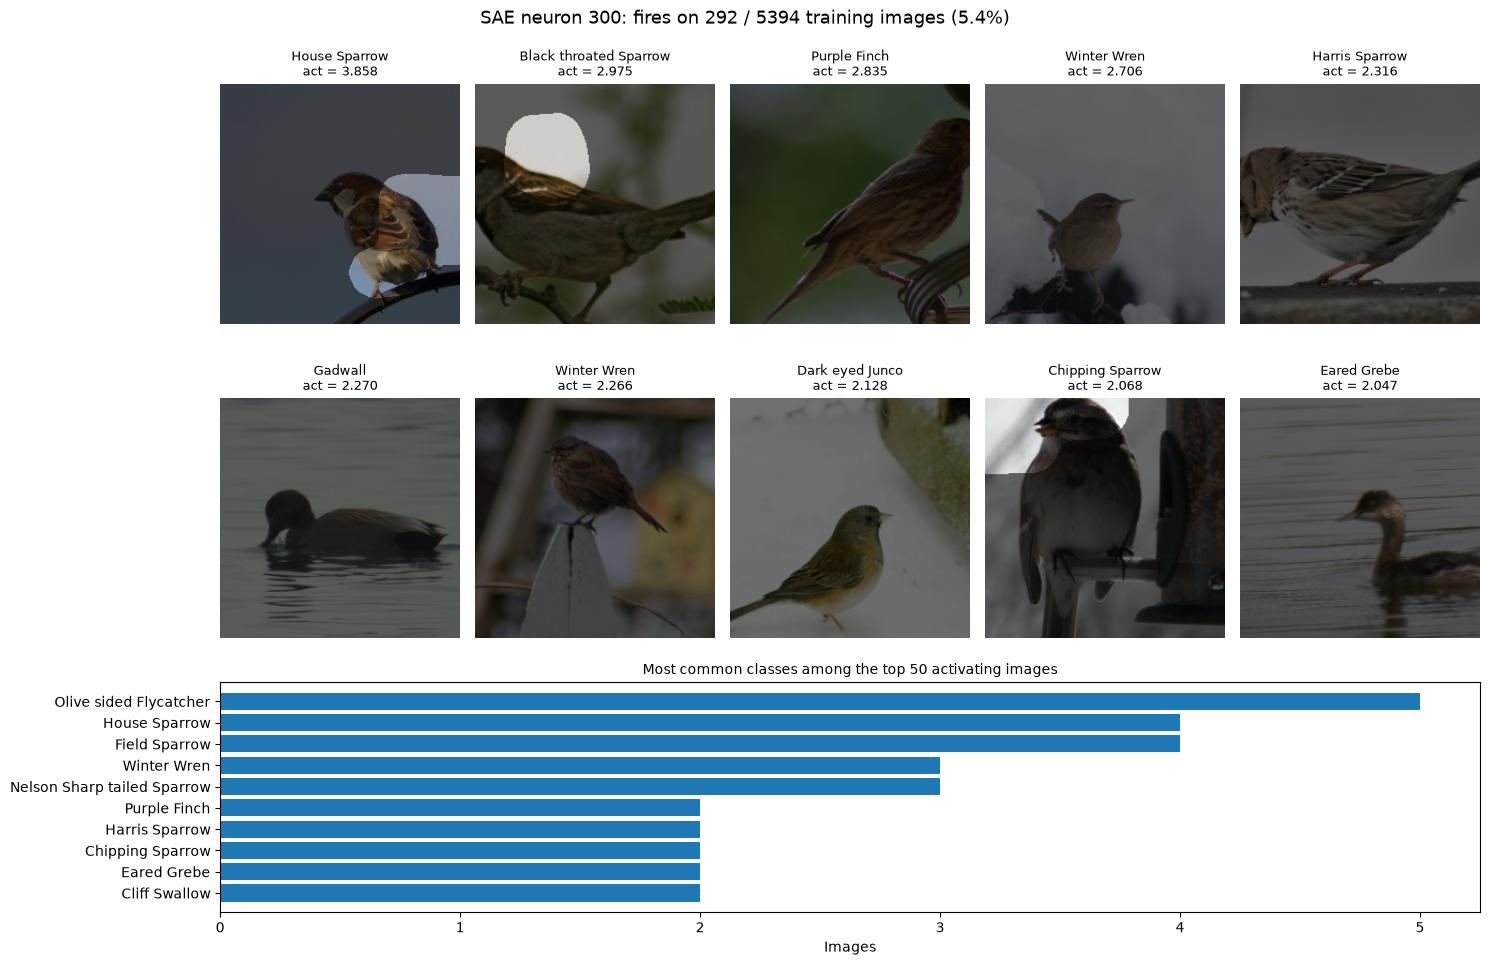

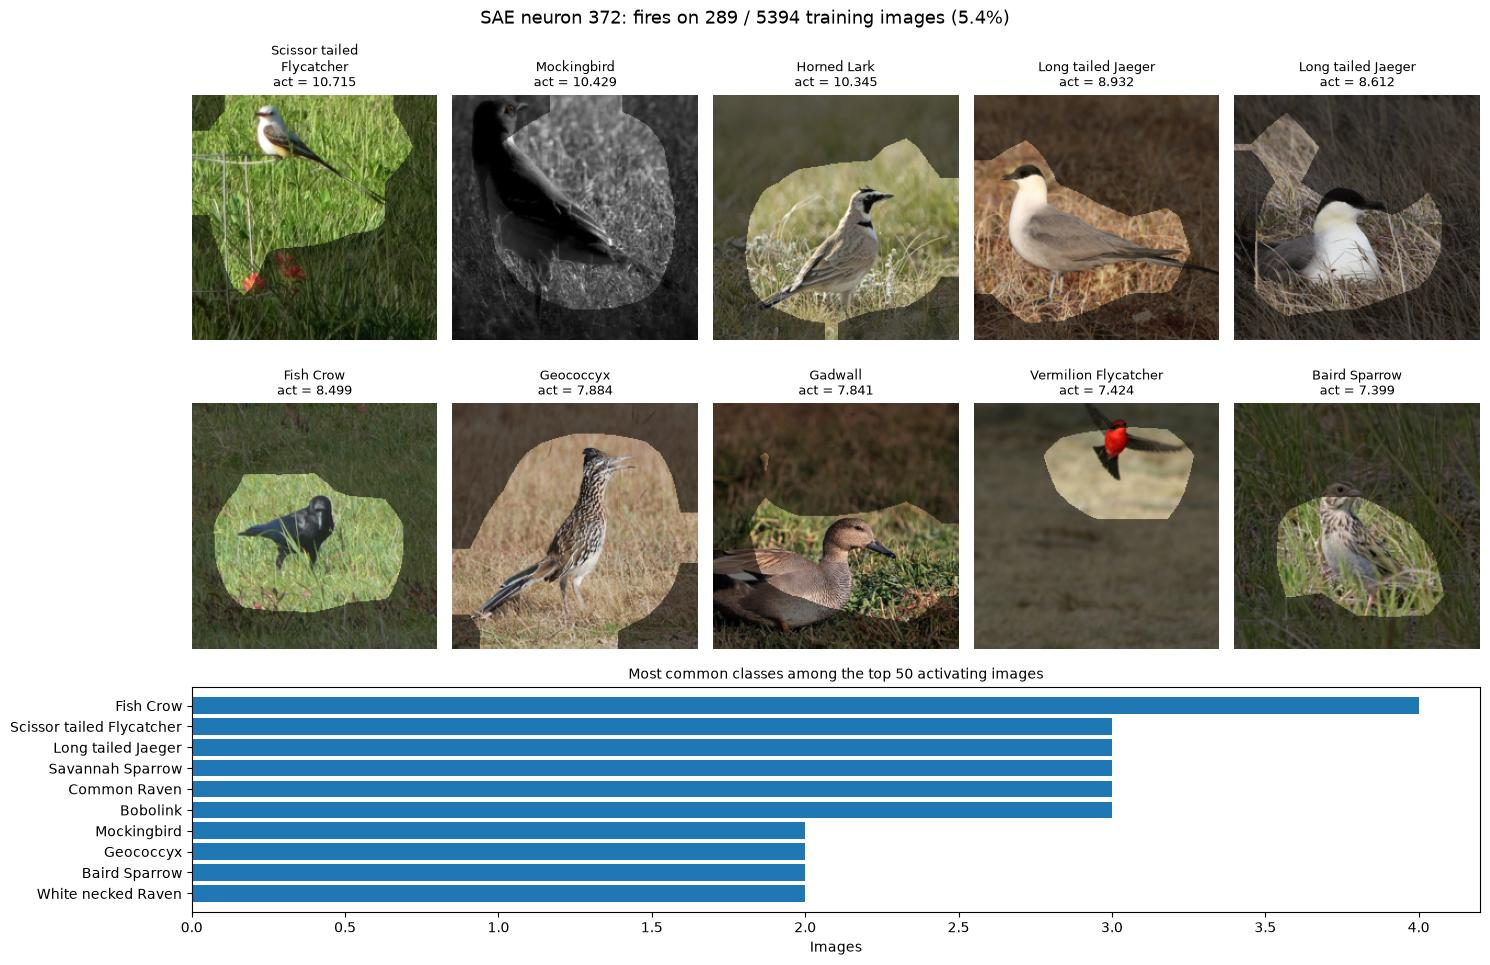

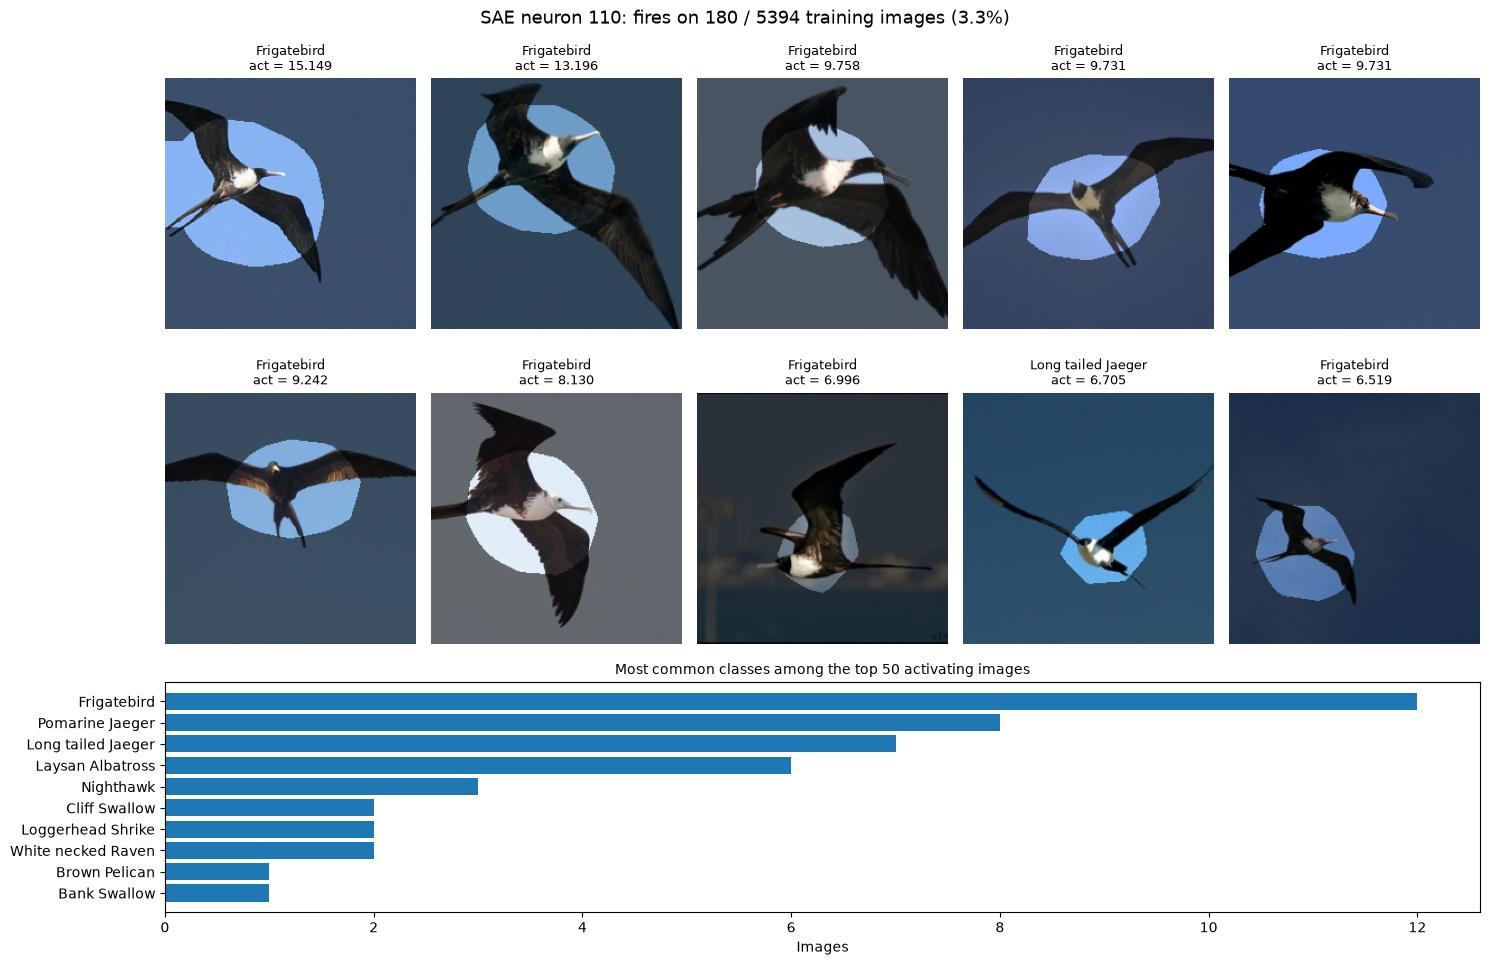

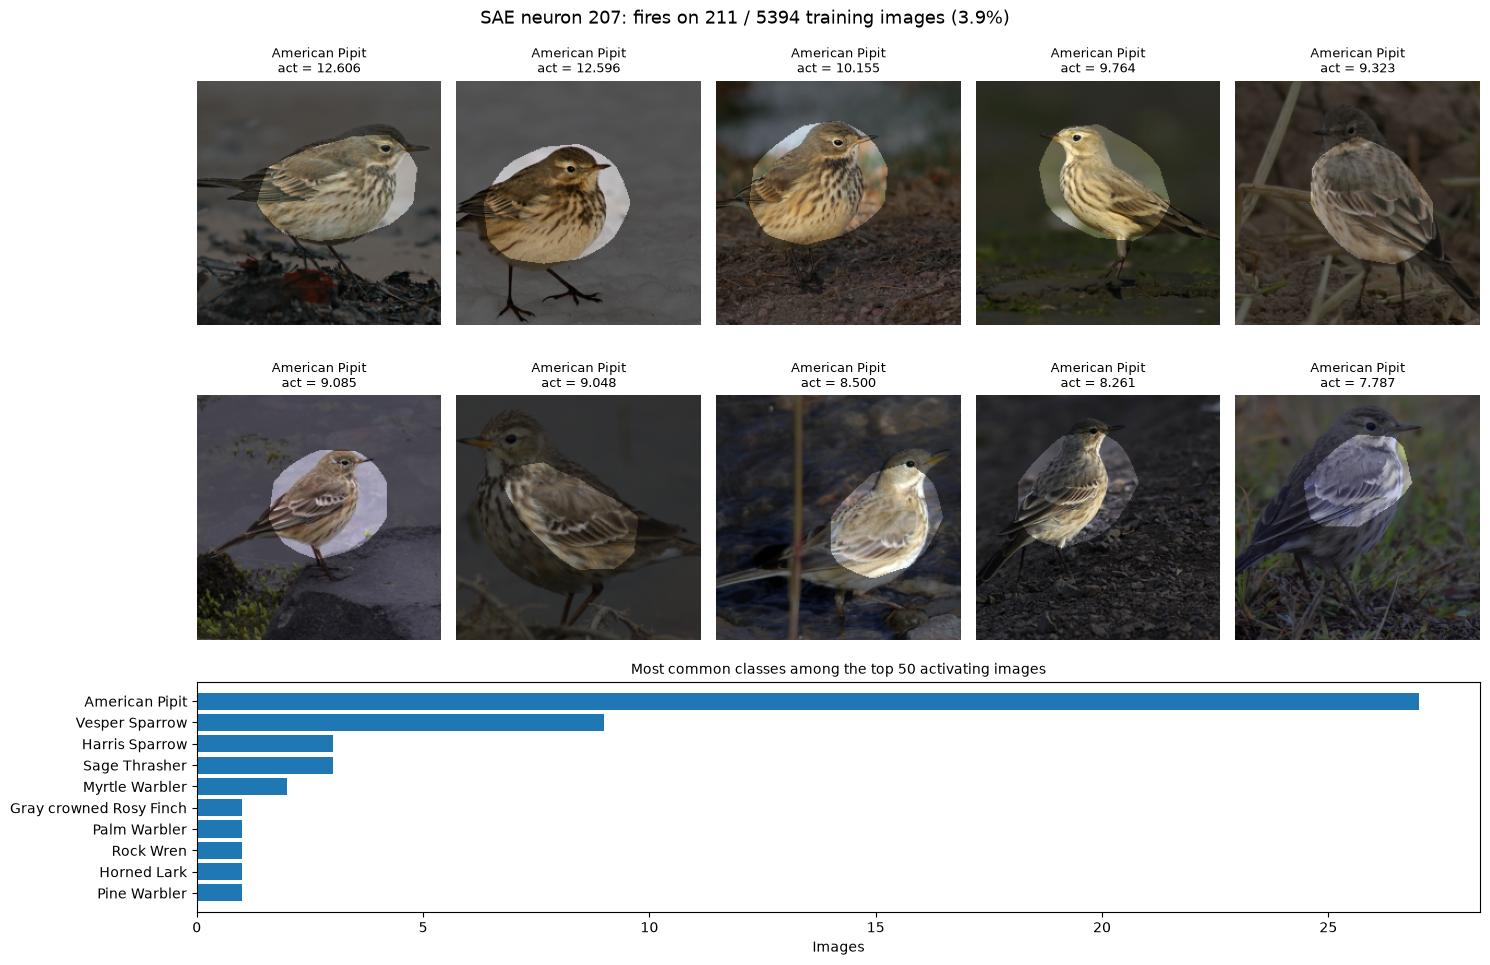

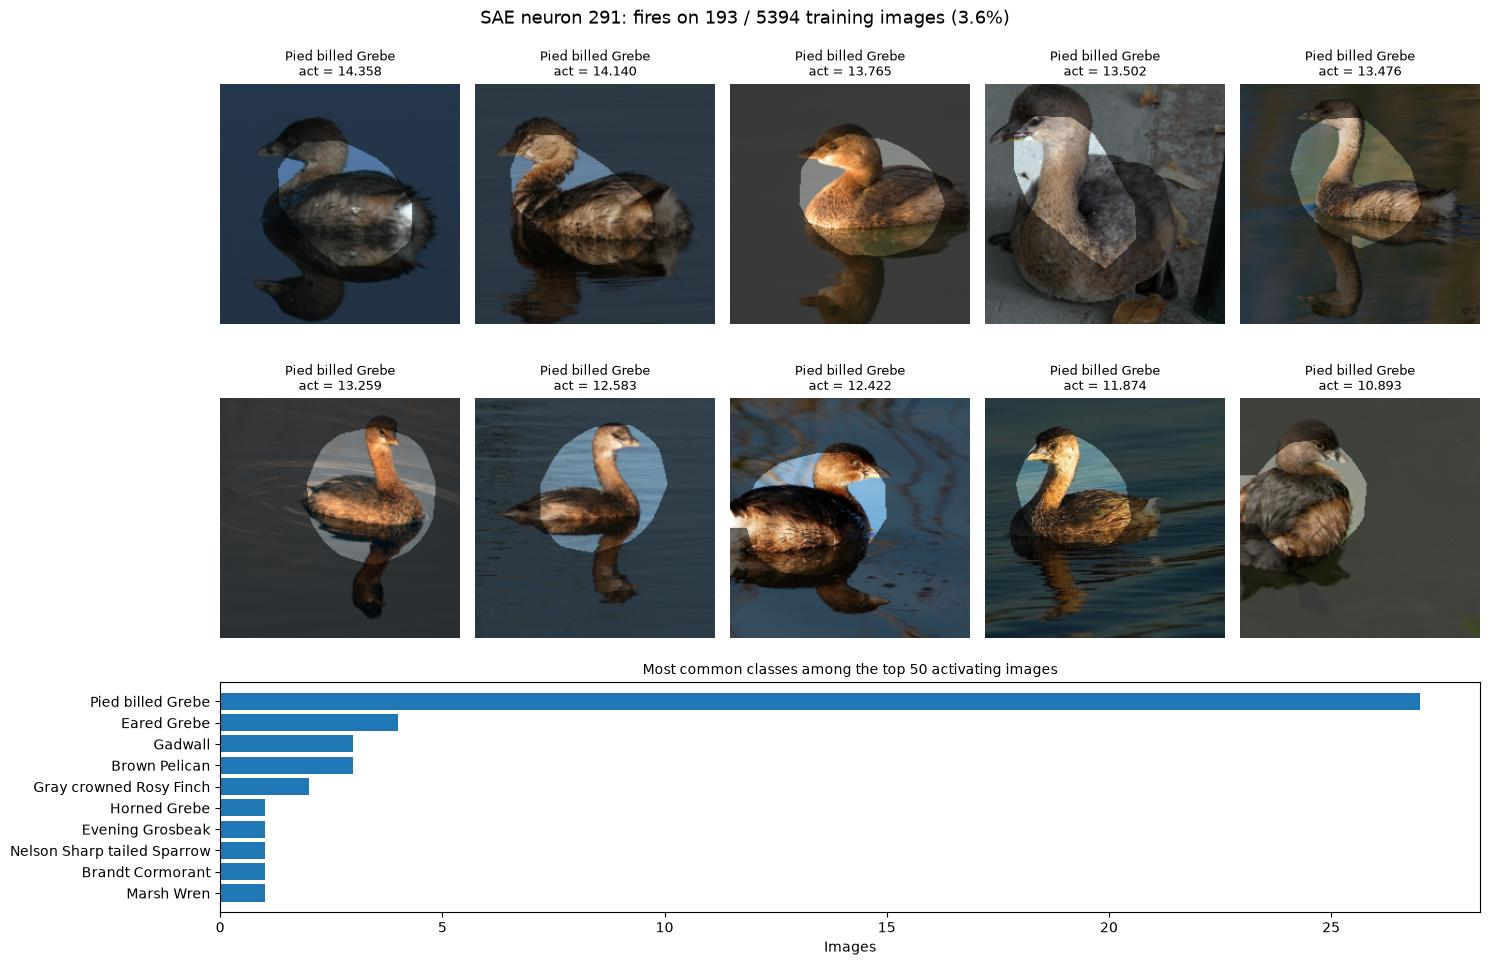

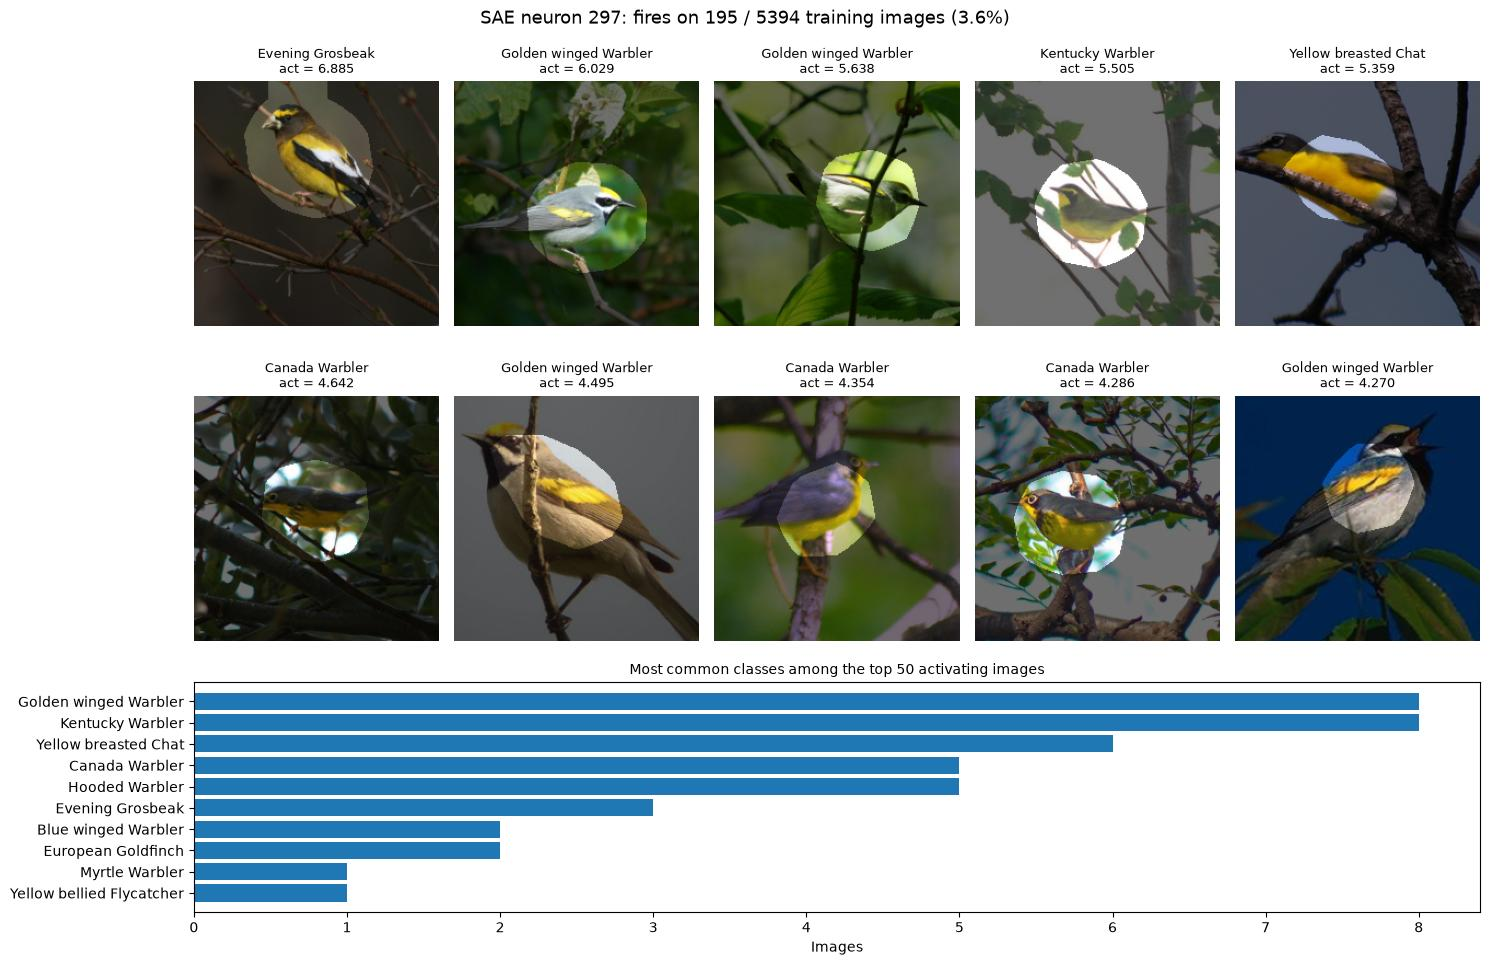

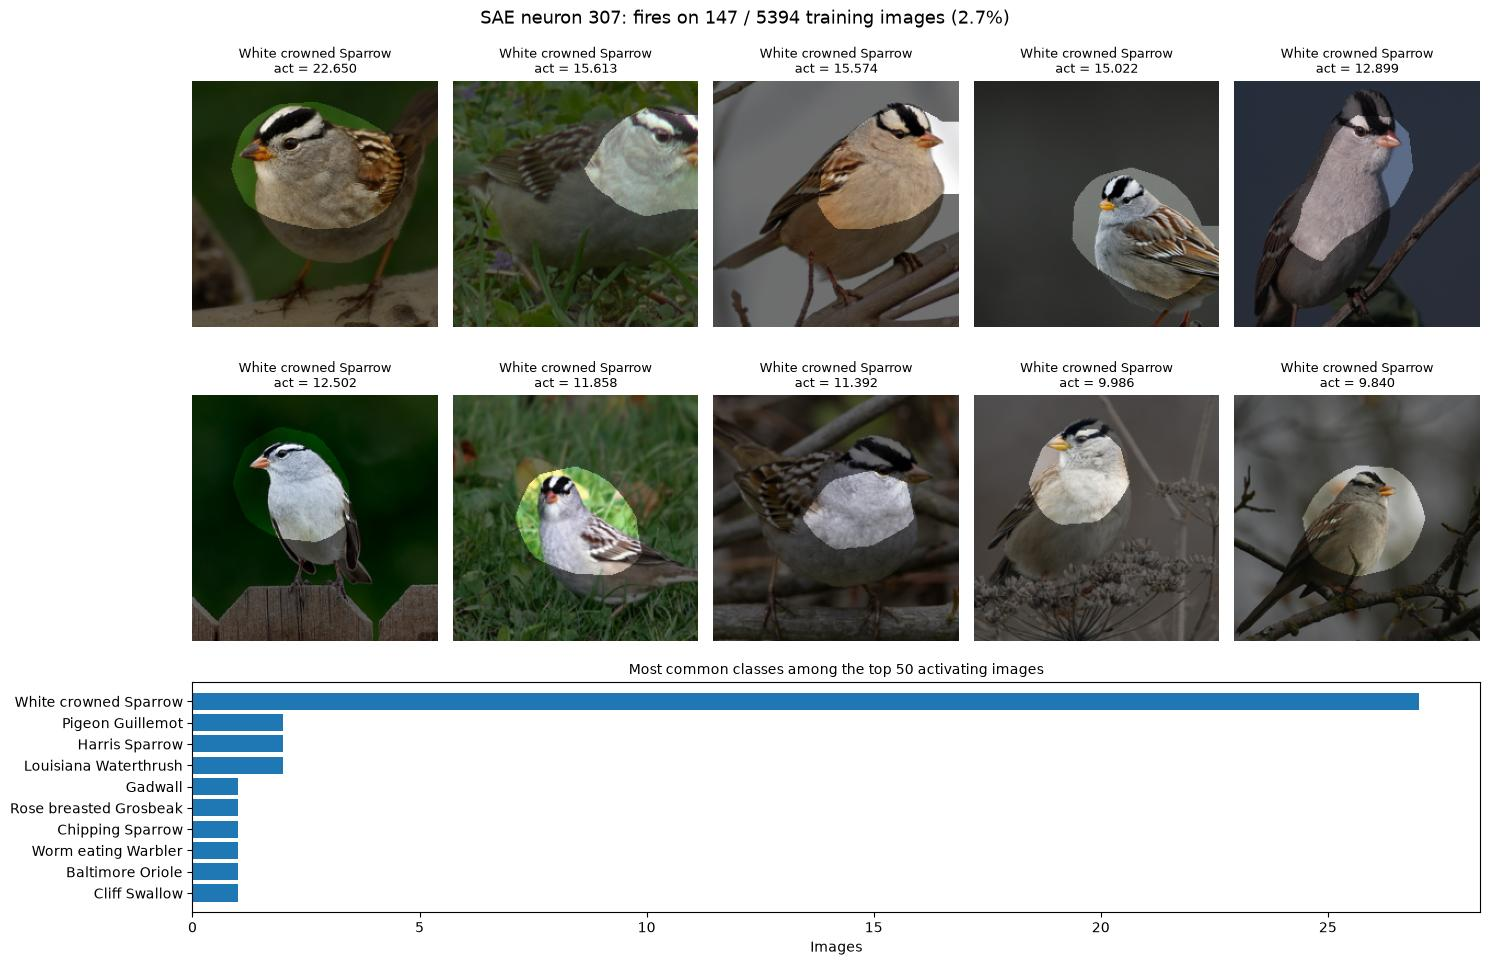

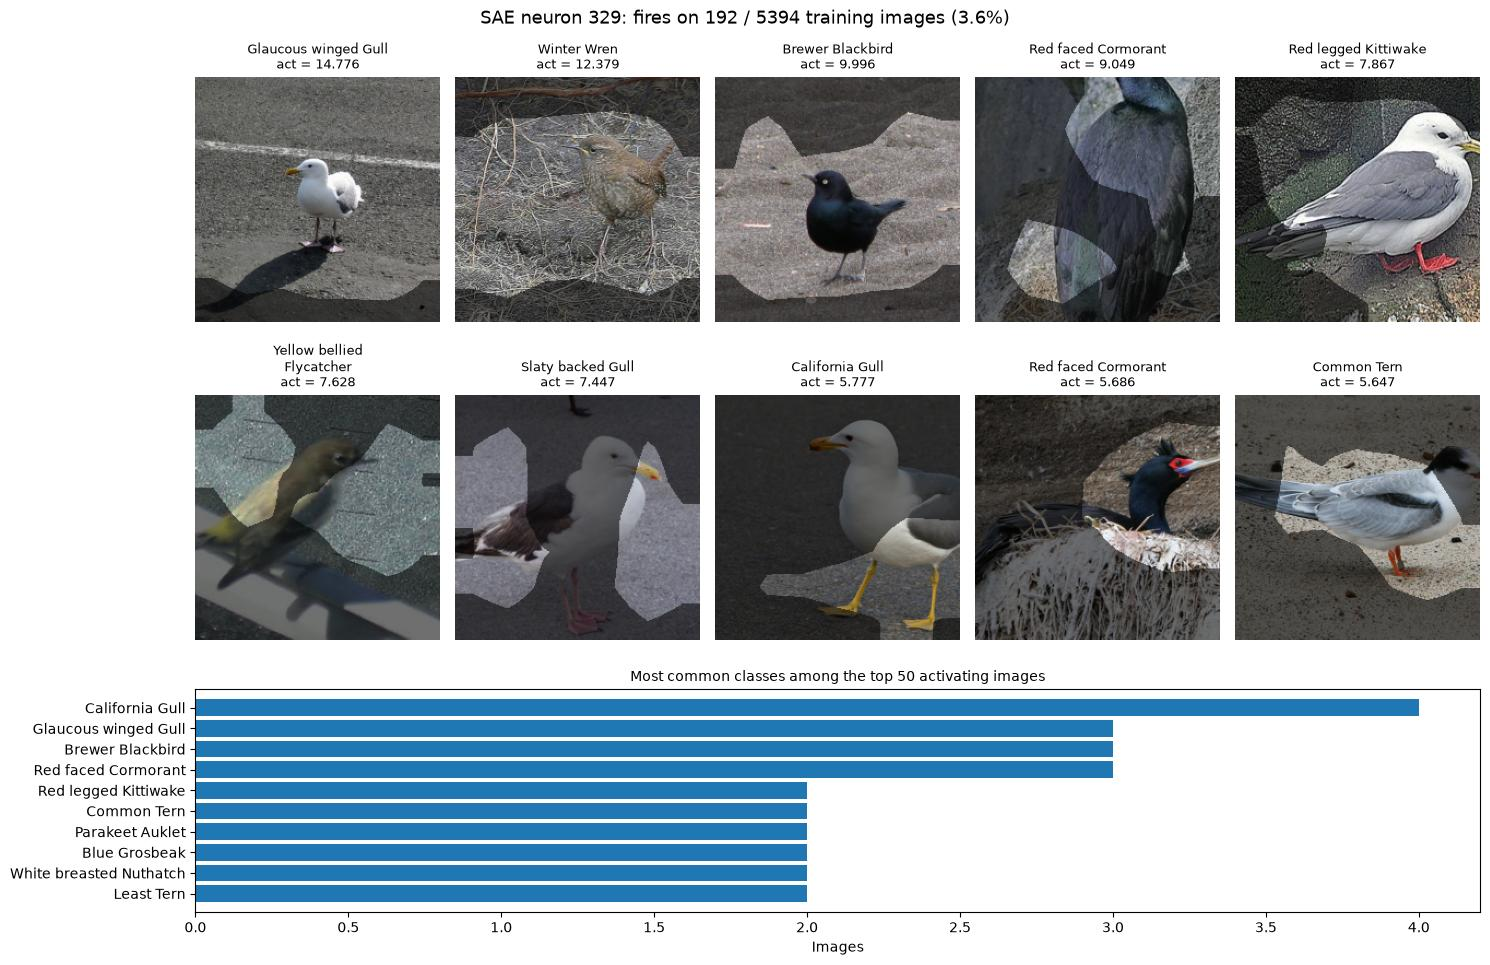

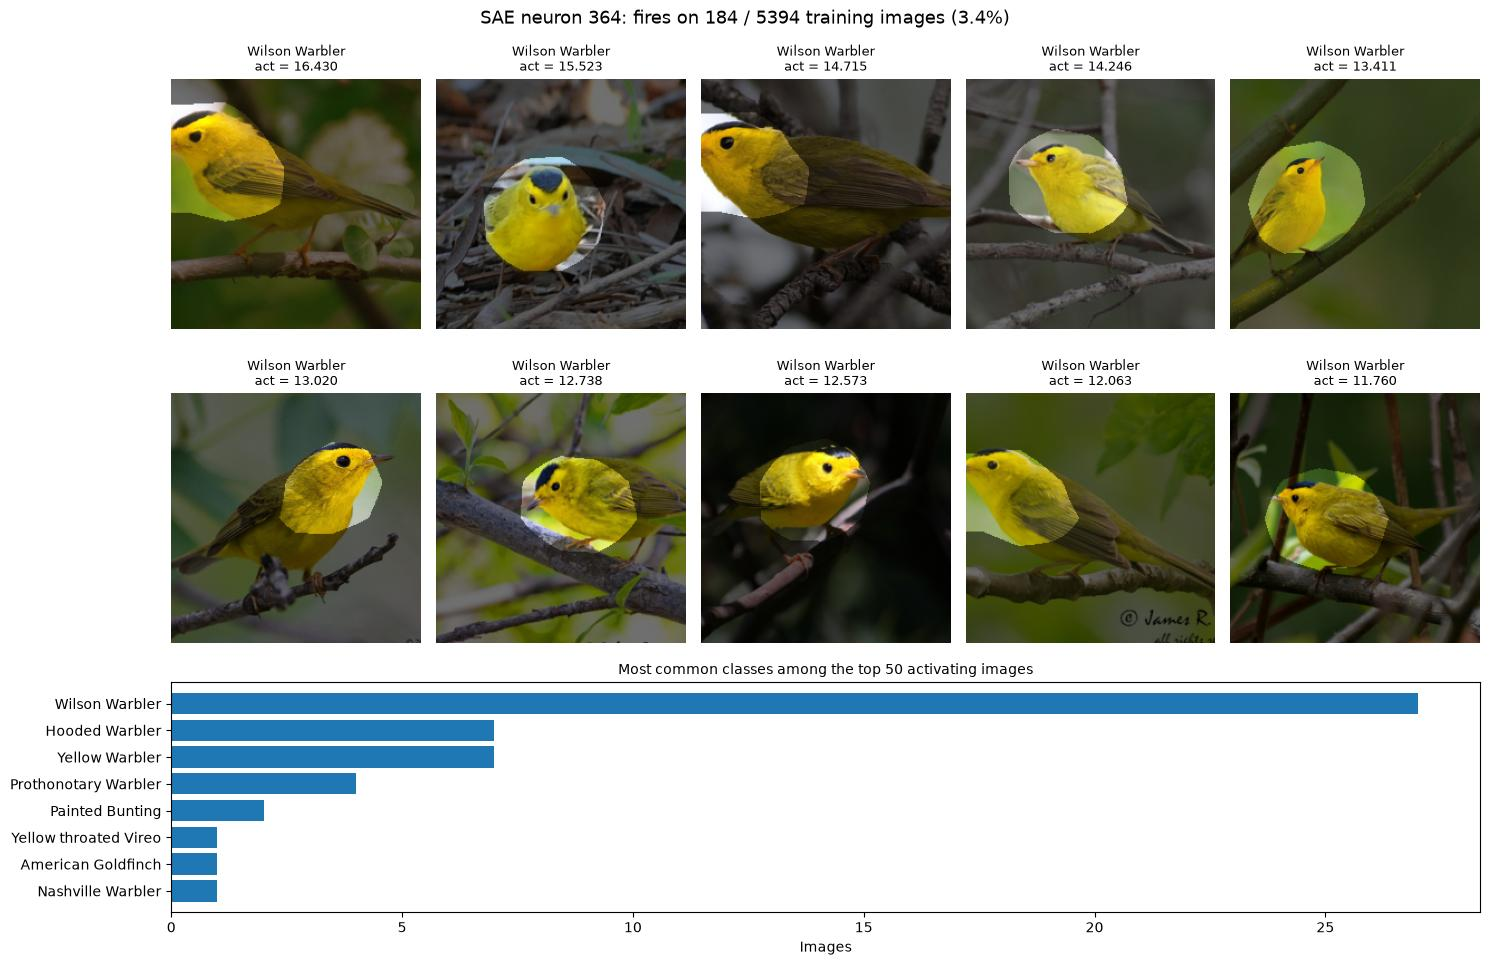

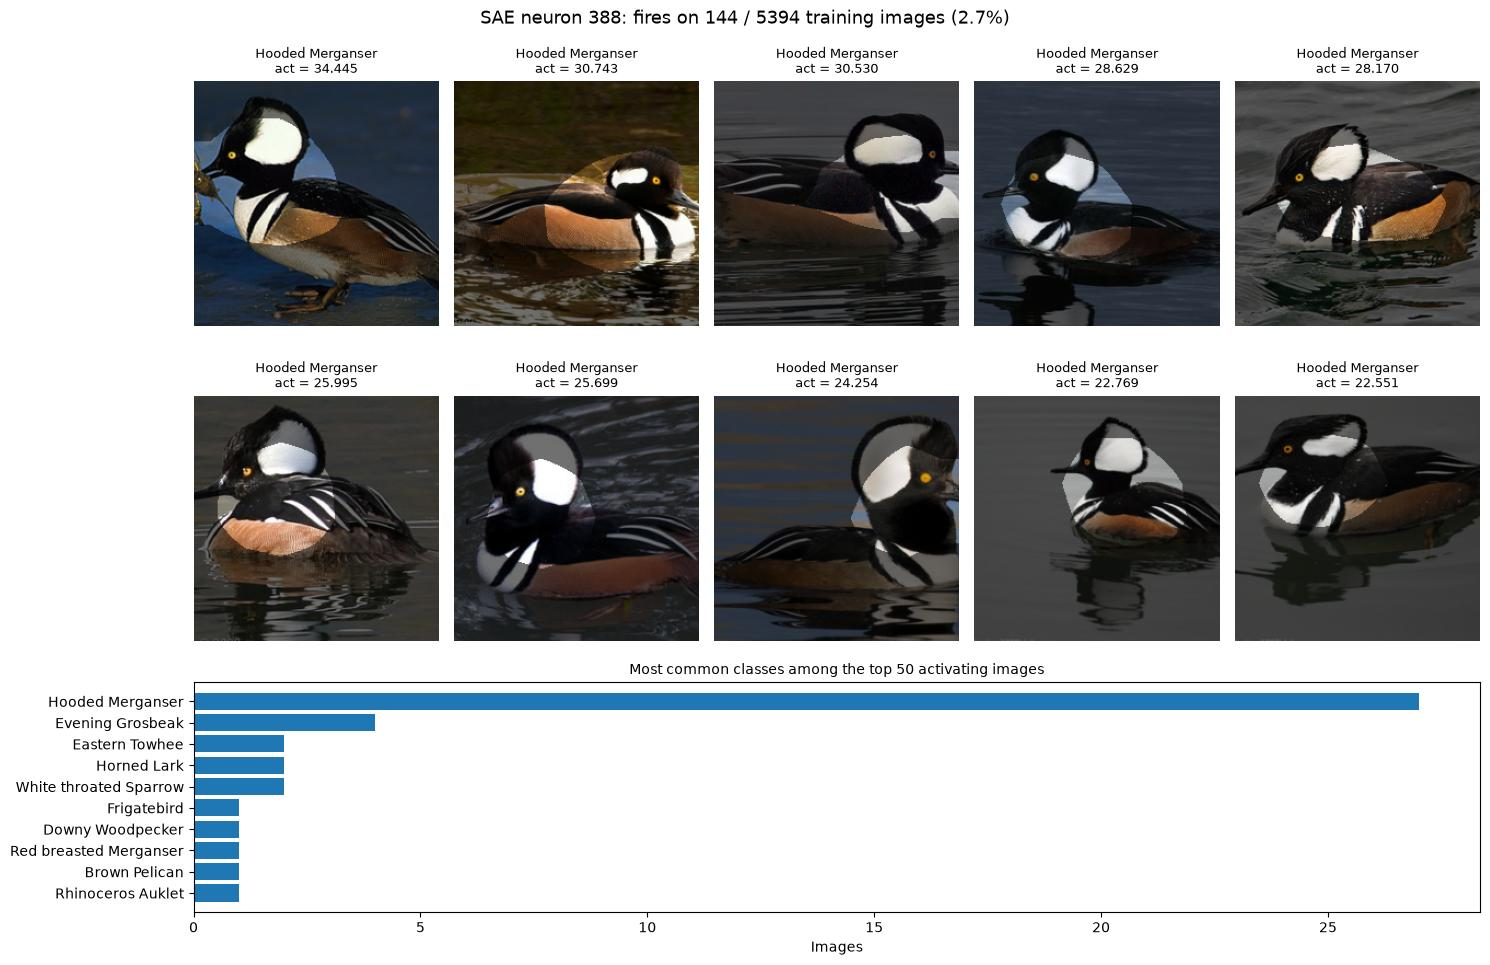

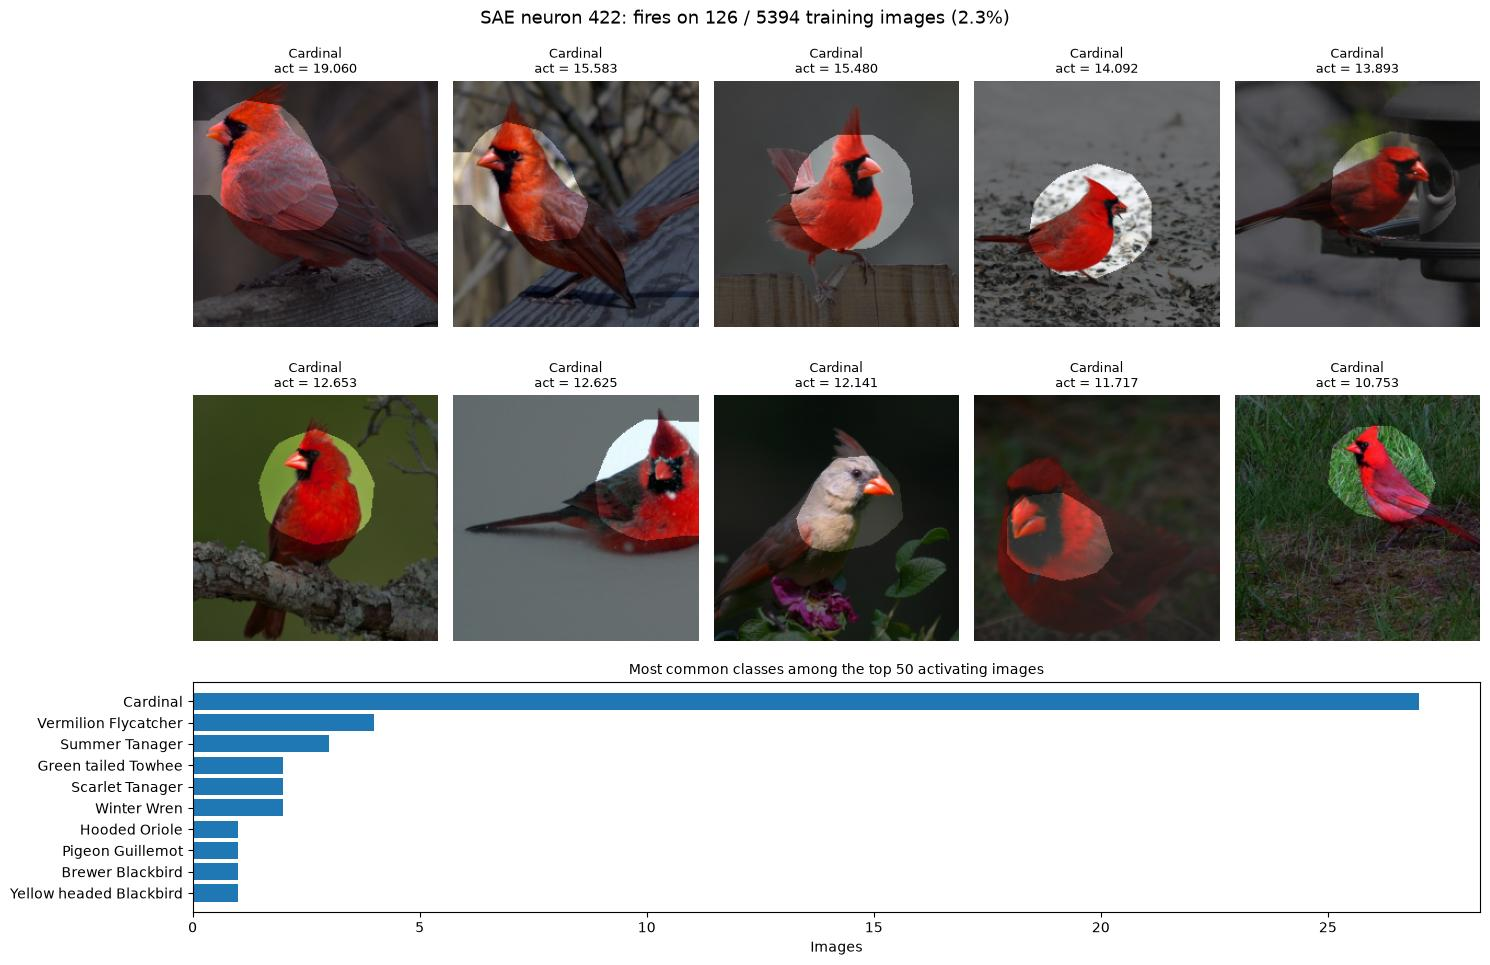

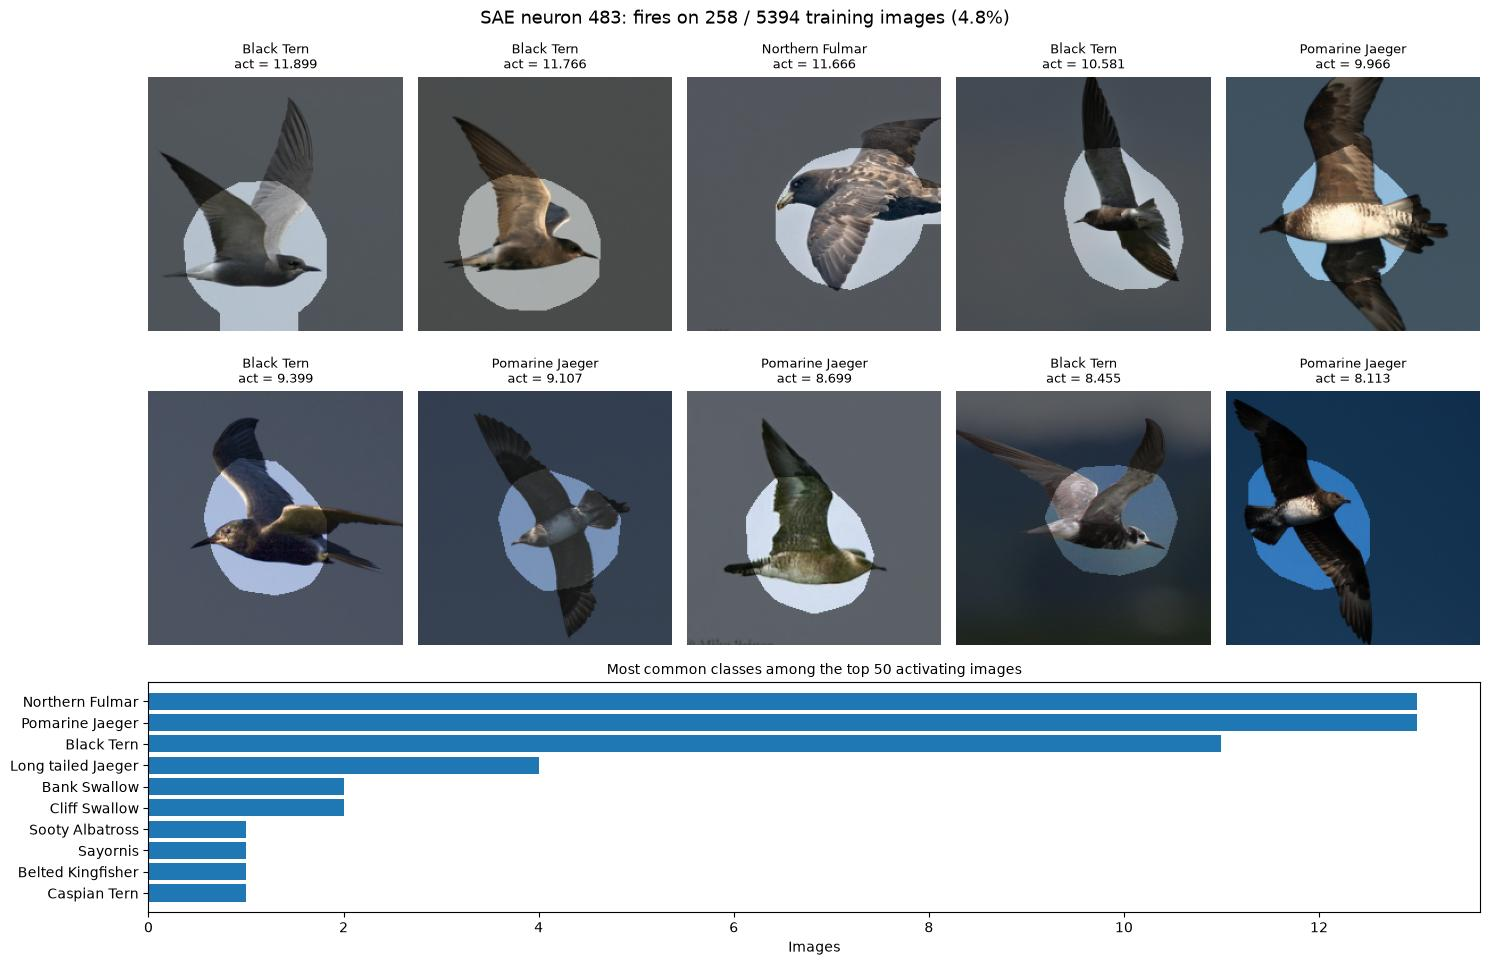

In [7]:
import random

N_NEURONS = 10
N_RANDOM = 10

by_frequency = explorer.neurons_by_frequency()
gallery = by_frequency[:N_NEURONS] + sorted(random.Random(0).sample(by_frequency[N_NEURONS:], min(N_RANDOM, len(by_frequency) - N_NEURONS)))
for neuron in gallery:
    explorer.plot_neuron(neuron, k=10)
    plt.show()